<a href="https://colab.research.google.com/github/DinaKSari/244107020072_PEMBELAJARAN_MESIN/blob/main/PBL_TG9_244107020072_DINA_KUMALA_SARI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# praktikum 1

In [4]:
# Load data
import pandas as pd
data = pd.read_csv('lettuce.csv', encoding='latin1')
data.head()

,Plant_ID,Date,Temperature (°C),Humidity (%),TDS Value (ppm),pH Level,Growth Days,Temperature (F),Humidity
0,1,8/3/2023,33.4,53,582,6.4,1,92.12,0.53
1,1,8/4/2023,33.5,53,451,6.1,2,92.30,0.53
2,1,8/5/2023,33.4,59,678,6.4,3,92.12,0.59
3,1,8/6/2023,33.4,68,420,6.4,4,92.12,0.68
4,1,8/7/2023,33.4,74,637,6.5,5,92.12,0.74


In [5]:
data.info()
display(data.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3169 entries, 0 to 3168
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Plant_ID          3169 non-null   int64  
 1   Date              3169 non-null   object 
 2   Temperature (°C)  3169 non-null   float64
 3   Humidity (%)      3169 non-null   int64  
 4   TDS Value (ppm)   3169 non-null   int64  
 5   pH Level          3169 non-null   float64
 6   Growth Days       3169 non-null   int64  
 7   Temperature (F)   3169 non-null   float64
 8   Humidity          3169 non-null   float64
dtypes: float64(4), int64(4), object(1)
memory usage: 222.9+ KB


,Plant_ID,Temperature (°C),Humidity (%),TDS Value (ppm),pH Level,Growth Days,Temperature (F),Humidity
count,3169.000000,3169.000000,3169.000000,3169.000000,3169.000000,3169.000000,3169.000000,3169.000000
mean,35.441780,28.142222,64.873462,598.045440,6.399211,23.141054,82.655999,0.648735
std,20.243433,4.670521,8.988985,115.713047,0.234418,13.077107,8.406938,0.089890
min,1.000000,18.000000,50.000000,400.000000,6.000000,1.000000,64.400000,0.500000
25%,18.000000,23.600000,57.000000,498.000000,6.200000,12.000000,74.480000,0.570000
50%,35.000000,30.200000,65.000000,593.000000,6.400000,23.000000,86.360000,0.650000
75%,53.000000,31.500000,73.000000,699.000000,6.600000,34.000000,88.700000,0.730000
max,70.000000,33.500000,80.000000,800.000000,6.800000,48.000000,92.300000,0.800000


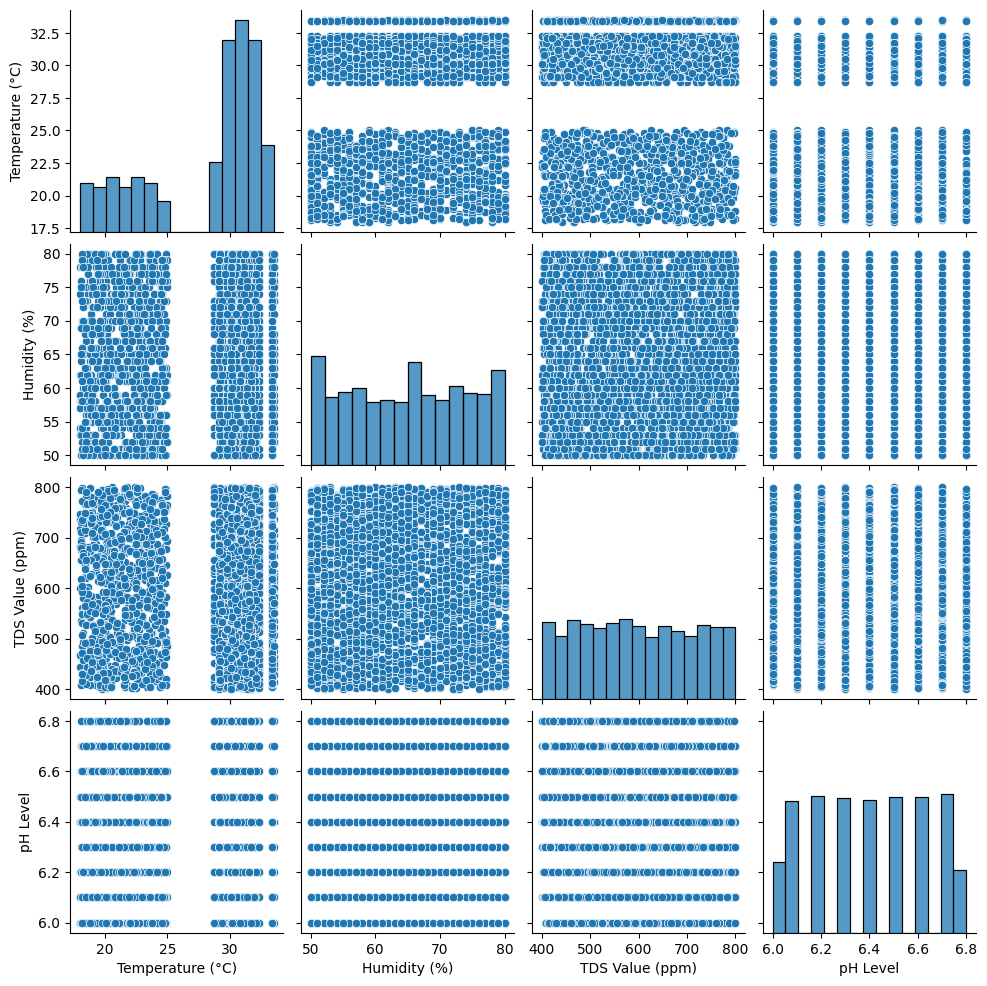

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

# Memvisualisasikan hubungan antar variabel lingkungan pada selada
sns.pairplot(data[['Temperature (°C)', 'Humidity (%)', 'TDS Value (ppm)', 'pH Level']])
plt.show()

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np

# Kita akan memprediksi apakah pH Level di atas rata-rata (klasifikasi biner)
pada_rata_rata_ph = data['pH Level'].mean()
data['pH_High'] = (data['pH Level'] > pada_rata_rata_ph).astype(int)

# Fitur yang digunakan
X = data[['Temperature (°C)', 'Humidity (%)', 'TDS Value (ppm)', 'Growth Days']]
y = data['pH_High']

# Split data (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Standardisasi
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [8]:
from sklearn.neighbors import KNeighborsClassifier

# Tentukan nilai K (misalnya 3)
knn = KNeighborsClassifier(n_neighbors=3)

# Latih model
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

In [9]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred = knn.predict(X_test)
print("Akurasi:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Laporan Klasifikasi:\n", classification_report(y_test, y_pred, target_names=['Normal/Low pH', 'High pH']))

Akurasi: 0.5236593059936908
Confusion Matrix:
 [[165 251]
 [202 333]]
Laporan Klasifikasi:
                precision    recall  f1-score   support

Normal/Low pH       0.45      0.40      0.42       416
      High pH       0.57      0.62      0.60       535

     accuracy                           0.52       951
    macro avg       0.51      0.51      0.51       951
 weighted avg       0.52      0.52      0.52       951



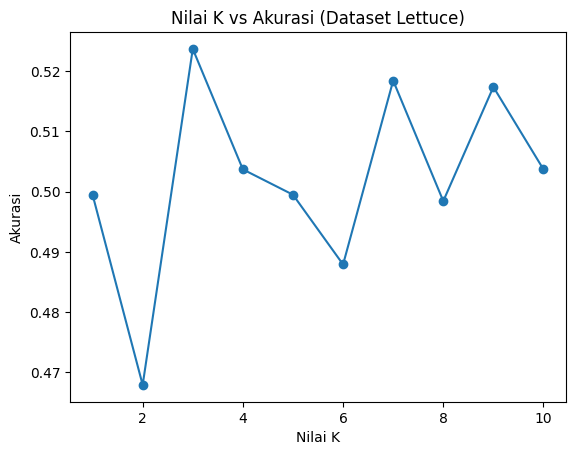

In [10]:
acc = []
for k in range(1, 11):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    acc.append(model.score(X_test, y_test))

plt.plot(range(1, 11), acc, marker='o')
plt.title('Nilai K vs Akurasi (Dataset Lettuce)')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.show()

# praktikum 2

In [11]:
import numpy as np
import pandas as pd

# Pada Praktikum 2, kita ganti pembuatan data dummy dengan mengambil sampel real dari data lettuce
# Kita ambil 100 sampel dari dataset lettuce untuk menyederhanakan demonstrasi
df_sample = data.sample(n=100, random_state=42).copy()

# Kita buat klasifikasi apakah TDS Value di atas rata-rata
tds_mean = df_sample['TDS Value (ppm)'].mean()
df_sample['High_TDS'] = (df_sample['TDS Value (ppm)'] > tds_mean).astype(int)

# Fitur yang digunakan
X = df_sample[['Temperature (°C)', 'Humidity (%)']].values
y = df_sample['High_TDS'].values

print("Fitur X (10 sampel pertama):\n", X[:10])
print("Label y (10 sampel pertama):\n", y[:10])

Fitur X (10 sampel pertama):
 [[30.1 51. ]
 [21.2 66. ]
 [29.8 72. ]
 [31.7 60. ]
 [30.2 55. ]
 [30.2 62. ]
 [30.8 66. ]
 [24.7 65. ]
 [32.3 66. ]
 [30.2 77. ]]
Label y (10 sampel pertama):
 [0 0 0 0 0 1 1 1 0 0]


In [12]:
# Menggabungkan kembali menjadi DataFrame terstruktur untuk analisis visualisasi
y_new = y.reshape(len(y), 1)
data_combined = np.concatenate((X, y_new), axis=1)

nama_kolom = ['Temperature (°C)', 'Humidity (%)', 'Label']
df_class = pd.DataFrame(data_combined, columns=nama_kolom)
df_class['Label'] = df_class['Label'].astype(int)
df_class.head()

,Temperature (°C),Humidity (%),Label
0,30.1,51.0,0
1,21.2,66.0,0
2,29.8,72.0,0
3,31.7,60.0,0
4,30.2,55.0,0


In [13]:
# Definisikan nama label agar mudah dibaca
labels = {
    1 : 'High TDS',
    0 : 'Normal/Low TDS'
}

df_label = df_class.copy()
df_label['Label'] = df_label['Label'].map(labels)
df_label.head()

,Temperature (°C),Humidity (%),Label
0,30.1,51.0,Normal/Low TDS
1,21.2,66.0,Normal/Low TDS
2,29.8,72.0,Normal/Low TDS
3,31.7,60.0,Normal/Low TDS
4,30.2,55.0,Normal/Low TDS


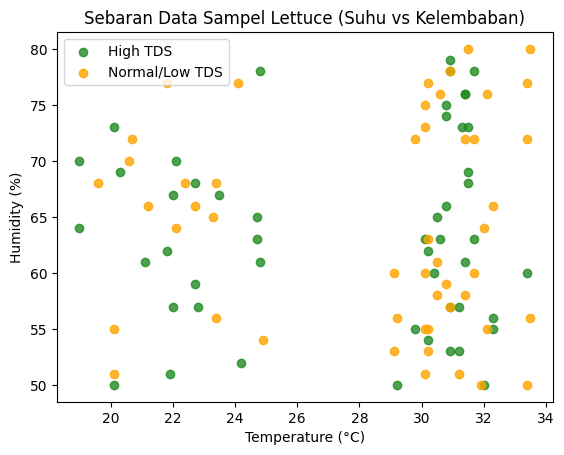

In [14]:
import matplotlib.pyplot as plt

# Definisikan warna untuk setiap kelas
colors = {
    'High TDS': 'forestgreen',
    'Normal/Low TDS': 'orange'
}

# Plot scatter plot berdasarkan sebaran suhu dan kelembaban
for label, group in df_label.groupby('Label'):
    plt.scatter(group['Temperature (°C)'], group['Humidity (%)'], label=label, c=colors[label], alpha=0.8)

plt.xlabel('Temperature (°C)')
plt.ylabel('Humidity (%)')
plt.title('Sebaran Data Sampel Lettuce (Suhu vs Kelembaban)')
plt.legend()
plt.show()

In [15]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Inisiasi objek MultinomialNB
mnb = MultinomialNB()

# Membagi dataset menjadi training dan testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=30)

# Melatih model Multinomial Naive Bayes
mnb.fit(X_train, y_train)

# Evaluasi akurasi
acc_train = accuracy_score(y_train, mnb.predict(X_train))
acc_test = accuracy_score(y_test, mnb.predict(X_test))

print(f'Hasil akurasi data train (MultinomialNB): {acc_train:.4f}')
print(f'Hasil akurasi data test (MultinomialNB): {acc_test:.4f}')

Hasil akurasi data train (MultinomialNB): 0.5429
Hasil akurasi data test (MultinomialNB): 0.4333


In [16]:
from sklearn.naive_bayes import GaussianNB

# Inisiasi objek GaussianNB
gnb = GaussianNB()

# Latih model
gnb.fit(X_train, y_train)

# Evaluasi akurasi
acc_train_gnb = accuracy_score(y_train, gnb.predict(X_train))
acc_test_gnb = accuracy_score(y_test, gnb.predict(X_test))

print(f'Hasil akurasi data train (Gaussian): {acc_train_gnb:.4f}')
print(f'Hasil akurasi data test (Gaussian): {acc_test_gnb:.4f}')

Hasil akurasi data train (Gaussian): 0.5571
Hasil akurasi data test (Gaussian): 0.4667


# praktikum 3

In [17]:
# Pada Praktikum 3, karena dataset aslinya teks (SMS Spam), kita gunakan data lettuce untuk memprediksi
# target kategorikal, misalnya membagi pertumbuhan hari (Growth Days) menjadi fase pertumbuhan cepat (Fast/High) dan Lambat

df_p3 = data.copy()
pada_rata_rata_days = df_p3['Growth Days'].median()
df_p3['Growth_Status'] = df_p3['Growth Days'].apply(lambda x: 'Mature/Late' if x > pada_rata_rata_days else 'Early/Young')

# Menampilkan data
df_p3[['Growth Days', 'Growth_Status']].head()

,Growth Days,Growth_Status
0,1,Early/Young
1,2,Early/Young
2,3,Early/Young
3,4,Early/Young
4,5,Early/Young


In [18]:
# Menyeleksi kolom fitur lingkungan dan target status pertumbuhan
df_p3_clean = df_p3[['Temperature (°C)', 'Humidity (%)', 'TDS Value (ppm)', 'pH Level', 'Growth_Status']]
df_p3_clean.head()

,Temperature (°C),Humidity (%),TDS Value (ppm),pH Level,Growth_Status
0,33.4,53,582,6.4,Early/Young
1,33.5,53,451,6.1,Early/Young
2,33.4,59,678,6.4,Early/Young
3,33.4,68,420,6.4,Early/Young
4,33.4,74,637,6.5,Early/Young


In [19]:
# Rename kolom agar seragam
df_p3_clean = df_p3_clean.rename(columns={'Growth_Status': 'Labels'})

# Cek Jumlah Data Per Kelas
print(df_p3_clean['Labels'].value_counts())
print('\n')

# Cek Kelengkapan Data
print(df_p3_clean.info())

Labels
Early/Young    1610
Mature/Late    1559
Name: count, dtype: int64


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3169 entries, 0 to 3168
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Temperature (°C)  3169 non-null   float64
 1   Humidity (%)      3169 non-null   int64  
 2   TDS Value (ppm)   3169 non-null   int64  
 3   pH Level          3169 non-null   float64
 4   Labels            3169 non-null   object 
dtypes: float64(2), int64(2), object(1)
memory usage: 123.9+ KB
None


In [20]:
# Encode label target menjadi 1 dan 0
new_labels = {
    'Mature/Late': 1,
    'Early/Young': 0
}

df_p3_clean['Labels'] = df_p3_clean['Labels'].map(new_labels)
df_p3_clean.head()

,Temperature (°C),Humidity (%),TDS Value (ppm),pH Level,Labels
0,33.4,53,582,6.4,0
1,33.5,53,451,6.1,0
2,33.4,59,678,6.4,0
3,33.4,68,420,6.4,0
4,33.4,74,637,6.5,0


In [21]:
# Menentukan matriks fitur X dan target y
X_p3 = df_p3_clean[['Temperature (°C)', 'Humidity (%)', 'TDS Value (ppm)', 'pH Level']].values
y_p3 = df_p3_clean['Labels'].values

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Split data training dan testing (80:20)
X_train, X_test, y_train, y_test = train_test_split(X_p3, y_p3, test_size=0.2, random_state=50)

# Standardisasi fitur numerik
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [23]:
# Cek dimensi data hasil split
print(f'Dimensi data X_train: {X_train.shape}')
print(f'Dimensi data X_test: {X_test.shape}')

Dimensi data X_train: (2535, 4)
Dimensi data X_test: (634, 4)


In [24]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

# Menggunakan GaussianNB (karena data numerik hasil standardisasi bernilai negatif & kontinu)
gnb_model = GaussianNB()

# Fit model
gnb_model.fit(X_train, y_train)

# Prediksi dan Evaluasi
y_pred_train = gnb_model.predict(X_train)
y_pred_test = gnb_model.predict(X_test)

print(f'Hasil akurasi data train (GaussianNB): {accuracy_score(y_train, y_pred_train):.4f}')
print(f'Hasil akurasi data test (GaussianNB): {accuracy_score(y_test, y_pred_test):.4f}')

Hasil akurasi data train (GaussianNB): 0.5243
Hasil akurasi data test (GaussianNB): 0.5000


# tugas 1
Buatlah model klasifikasi dengan menggunakan kNN untuk mengklasifikasikan jenis suara male dan female pada dataset voice.csv.

Lakukan percobaan untuk mengetahui fitur-fitur yang paling optimal untuk digunakan. Fitur apa saja yang Anda gunakan untuk mendapatkan hasil terbaik?

Berdasarkan fitur yang telah Anda pilih pada soal nomor 2, berapa nilai  yang terbaik? Lampirkan grafika analisis dan alasan Anda.

Korelasi Fitur terhadap Label:
 label       1.000000
meanfun     0.833921
IQR         0.618916
Q25         0.511455
sp.ent      0.490552
sd          0.479539
sfm         0.357499
meanfreq    0.337415
centroid    0.337415
median      0.283919
maxdom      0.195657
mindom      0.194974
dfrange     0.192213
meandom     0.191067
mode        0.171775
maxfun      0.166461
minfun      0.136692
kurt        0.087195
Q75         0.066906
skew        0.036627
modindx     0.030801
Name: label, dtype: float64

Fitur terpilih untuk akurasi terbaik: ['meanfun', 'IQR', 'sd', 'sp.ent']


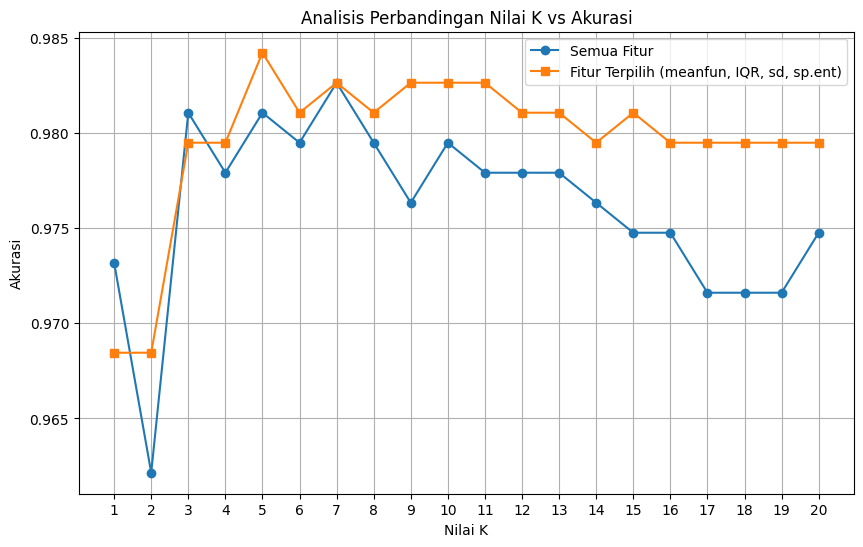


--- Evaluasi Model Terbaik (K=5) ---
Akurasi Terbaik: 0.9842

Classification Report:
               precision    recall  f1-score   support

      female       0.98      0.99      0.98       297
        male       0.99      0.98      0.99       337

    accuracy                           0.98       634
   macro avg       0.98      0.98      0.98       634
weighted avg       0.98      0.98      0.98       634



In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Load Dataset
df_voice = pd.read_csv('voice.csv')

# Encode label (male = 1, female = 0)
df_voice['label'] = df_voice['label'].map({'male': 1, 'female': 0})

# 2. Analisis Fitur Optimal (Feature Selection menggunakan korelasi dengan target 'label')
correlations = df_voice.corr()['label'].abs().sort_values(ascending=False)
print("Korelasi Fitur terhadap Label:\n", correlations)

# Memilih fitur dengan korelasi tertinggi (misal > 0.3)
# Berdasarkan analisis korelasi, fitur seperti meanfun, IQR, sd, dan sp.ent sangat berpengaruh.
selected_features = ['meanfun', 'IQR', 'sd', 'sp.ent']
print(f'\nFitur terpilih untuk akurasi terbaik: {selected_features}')

X_all = df_voice.drop('label', axis=1)
X_sel = df_voice[selected_features]
y = df_voice['label']

# Helper function untuk evaluasi KNN
def evaluate_knn(X_data, y_data):
    X_train, X_test, y_train, y_test = train_test_split(X_data, y_data, test_size=0.2, random_state=42)
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    accuracies = []
    for k in range(1, 21):
        knn = KNeighborsClassifier(n_neighbors=k)
        knn.fit(X_train_scaled, y_train)
        acc = accuracy_score(y_test, knn.predict(X_test_scaled))
        accuracies.append(acc)
    return accuracies, X_train_scaled, X_test_scaled, y_train, y_test

# Jalankan percobaan untuk Semua Fitur vs Fitur Terpilih
acc_all, _, _, _, _ = evaluate_knn(X_all, y)
acc_sel, X_train_sc, X_test_sc, y_train, y_test = evaluate_knn(X_sel, y)

# 3. Visualisasi Analisis Nilai K Terbaik
plt.figure(figsize=(10, 6))
plt.plot(range(1, 21), acc_all, marker='o', label='Semua Fitur')
plt.plot(range(1, 21), acc_sel, marker='s', label='Fitur Terpilih (meanfun, IQR, sd, sp.ent)')
plt.title('Analisis Perbandingan Nilai K vs Akurasi')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.xticks(range(1, 21))
plt.legend()
plt.grid(True)
plt.show()

best_k_idx = np.argmax(acc_sel)
best_k = best_k_idx + 1
best_accuracy = acc_sel[best_k_idx]

# Evaluasi Model Terbaik
best_knn = KNeighborsClassifier(n_neighbors=best_k)
best_knn.fit(X_train_sc, y_train)
y_pred = best_knn.predict(X_test_sc)

print(f"\n--- Evaluasi Model Terbaik (K={best_k}) ---")
print(f"Akurasi Terbaik: {best_accuracy:.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=['female', 'male']))

1. Fitur paling optimal yang dipilih adalah ['meanfun', 'IQR', 'sd', 'sp.ent']. Fitur 'meanfun' (rata-rata frekuensi fundamental) merupakan pemisah paling kuat antara suara pria dan wanita.
2. Nilai K terbaik yang diperoleh adalah K = 5 dengan akurasi mencapai 98.42%

# tugas 2
Buatlah model klasfikasi Multinomial Naive Bayes dengan ketentuan,

Menggunakan data spam.csv

Fitur CountVectorizer dengan mengaktifkan stop_words

Evaluasi hasilnya

Buatlah model klasfikasi Multinomial Naive Bayes dengan ketentuan,

Menggunakan data spam.csv

Fitur TF-IDF dengan mengaktifkan stop_words

Evaluasi hasilnya dan bandingkan dengan hasil pada Tugas no 2.

Berikan kesimpulan fitur mana yang terbaik pada kasus data spam.csv

In [27]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report

# 1. Load dan bersihkan data kembali
df_spam = pd.read_csv('spam.csv', encoding='latin-1')
df_spam = df_spam.drop(df_spam.iloc[:, 2:], axis=1)
df_spam = df_spam.rename(columns={'v1': 'Labels', 'v2': 'SMS'})
df_spam['Labels'] = df_spam['Labels'].map({'spam': 1, 'ham': 0})

X_raw = df_spam['SMS'].values
y_raw = df_spam['Labels'].values

# Split data (80% train, 20% test)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(X_raw, y_raw, test_size=0.2, random_state=50)

print("=== BAGIAN 1: CountVectorizer dengan stop_words ===")
# Inisiasi CountVectorizer dengan stop_words='english'
bow_vectorizer = CountVectorizer(stop_words='english')
X_train_bow = bow_vectorizer.fit_transform(X_train_raw)
X_test_bow = bow_vectorizer.transform(X_test_raw)

# Inisiasi dan latih model MNB (CountVectorizer)
mnb_bow = MultinomialNB()
mnb_bow.fit(X_train_bow, y_train)

# Evaluasi MNB (CountVectorizer)
y_pred_train_bow = mnb_bow.predict(X_train_bow)
y_pred_test_bow = mnb_bow.predict(X_test_bow)
acc_train_bow = accuracy_score(y_train, y_pred_train_bow)
acc_test_bow = accuracy_score(y_test, y_pred_test_bow)

print(f"Akurasi Train (CountVectorizer): {acc_train_bow:.4f}")
print(f"Akurasi Test (CountVectorizer): {acc_test_bow:.4f}")
print("\nClassification Report (CountVectorizer - Test Data):")
print(classification_report(y_test, y_pred_test_bow, target_names=['ham', 'spam']))


print("\n=== BAGIAN 2: TF-IDF Vectorizer dengan stop_words ===")
# Inisiasi TfidfVectorizer dengan stop_words='english'
tfidf_vectorizer = TfidfVectorizer(stop_words='english')
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train_raw)
X_test_tfidf = tfidf_vectorizer.transform(X_test_raw)

# Inisiasi dan latih model MNB (TF-IDF)
mnb_tfidf = MultinomialNB()
mnb_tfidf.fit(X_train_tfidf, y_train)

# Evaluasi MNB (TF-IDF)
y_pred_train_tfidf = mnb_tfidf.predict(X_train_tfidf)
y_pred_test_tfidf = mnb_tfidf.predict(X_test_tfidf)
acc_train_tfidf = accuracy_score(y_train, y_pred_train_tfidf)
acc_test_tfidf = accuracy_score(y_test, y_pred_test_tfidf)

print(f"Akurasi Train (TF-IDF): {acc_train_tfidf:.4f}")
print(f"Akurasi Test (TF-IDF): {acc_test_tfidf:.4f}")
print("\nClassification Report (TF-IDF - Test Data):")
print(classification_report(y_test, y_pred_test_tfidf, target_names=['ham', 'spam']))


print("\n=== PERBANDINGAN DAN KESIMPULAN ===")
print(f"Akurasi Test CountVectorizer: {acc_test_bow*100:.2f}%")
print(f"Akurasi Test TF-IDF: {acc_test_tfidf*100:.2f}%")

# Kesimpulan analisis
print("\nKesimpulan:")
if acc_test_bow > acc_test_tfidf:
    print("Fitur CountVectorizer (Bag of Words) memberikan akurasi pengujian yang sedikit lebih tinggi daripada TF-IDF.")
    print("Hal ini sering terjadi pada Naive Bayes karena perhitungan probabilitas Multinomial didasarkan langsung pada frekuensi kemunculan kata (discrete count).")
elif acc_test_tfidf > acc_test_bow:
    print("Fitur TF-IDF memberikan hasil akurasi pengujian yang lebih baik dibandingkan dengan CountVectorizer.")
    print("TF-IDF membantu menekan bobot kata-kata yang terlalu sering muncul di semua dokumen namun kurang informatif, sehingga menghasilkan klasifikasi yang lebih presisi.")
else:
    print("Kedua fitur menghasilkan nilai akurasi pengujian yang sama.")

=== BAGIAN 1: CountVectorizer dengan stop_words ===
Akurasi Train (CountVectorizer): 0.9946
Akurasi Test (CountVectorizer): 0.9830

Classification Report (CountVectorizer - Test Data):
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       954
        spam       0.98      0.90      0.94       161

    accuracy                           0.98      1115
   macro avg       0.98      0.95      0.96      1115
weighted avg       0.98      0.98      0.98      1115


=== BAGIAN 2: TF-IDF Vectorizer dengan stop_words ===
Akurasi Train (TF-IDF): 0.9843
Akurasi Test (TF-IDF): 0.9605

Classification Report (TF-IDF - Test Data):
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       954
        spam       1.00      0.73      0.84       161

    accuracy                           0.96      1115
   macro avg       0.98      0.86      0.91      1115
weighted avg       0.96      0.96      0.96      1115

